# Kalman Filter Parameter Sweep

Results from phased parameter tuning of the 3D ball-tracking Kalman filter.

Each phase isolates one parameter dimension, finds the best value, then locks it
for subsequent phases.

## How to use

1. In `src/evaluate.py`, set `PHASE` and `CONFIGS` for the phase you want to run.
2. Run the sweep inside Docker:  
   ```bash
   docker compose run perception-x86 bash -lc "python src/evaluate.py"
   ```
3. Results are saved to `output/sweep_phase_N.csv` and `output/ade_fde_phase_N.png`.
4. Come back here, set `PHASE` below to the phase number, and run the cells to inspect.

In [100]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("../output")
PHASE = 4  # change this to view a different phase

In [101]:
%pip install -q pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## Load results

In [102]:
csv_path = OUTPUT_DIR / f"sweep_phase_{PHASE}.csv"
df = pd.read_csv(csv_path)
print(f"Loaded {csv_path} - {len(df)} rows")
df.head()

Loaded ../output/sweep_phase_4.csv - 60 rows


,config,model,velocity_process_noise,position_process_noise,acceleration_process_noise,measurement_noise_x,measurement_noise_y,measurement_noise_z,sequence,n,mean_ade_m,mean_fde_m,max_ade_m,max_fde_m,latency_mean_ms,latency_p95_ms,latency_max_ms,throughput_fps,ram_peak_mb,gpu_peak_mb
0,cv_optimized,CV,0.02,0.0001,NaN,0.000064,0.000121,0.000064,HD1080_one_ball_straight_line_21-34-15,65,0.0144,0.0237,0.0870,0.1394,10.71,9.00,327.83,30.65,2320.6,396.4
1,cv_optimized,CV,0.02,0.0001,NaN,0.000064,0.000121,0.000064,HD1080_one_ball_diagonal_21-34-29,91,0.0061,0.0101,0.0369,0.0572,8.58,8.79,8.81,35.69,2439.9,346.4
2,cv_optimized,CV,0.02,0.0001,NaN,0.000064,0.000121,0.000064,HD1080_one_ball_diagonal_21-34-44,134,0.0068,0.0113,0.1718,0.2954,8.70,8.80,8.84,35.81,2487.3,346.4
3,cv_optimized,CV,0.02,0.0001,NaN,0.000064,0.000121,0.000064,HD1080_one_ball_diagonal_21-35-05,123,0.0072,0.0110,0.0437,0.0741,8.68,8.80,8.83,35.74,2556.3,346.4
4,cv_optimized,CV,0.02,0.0001,NaN,0.000064,0.000121,0.000064,HD1080_one_ball_diagonal_21-35-18,99,0.0110,0.0172,0.0459,0.0667,8.65,8.81,9.05,35.77,2559.9,346.4


## Config parameters

Which KF parameters were tested in this phase.

In [103]:
param_cols = [c for c in df.columns if c.endswith("_noise")]
if param_cols:
    configs = df.groupby("config")[param_cols].first().reset_index()
    display(configs)
else:
    print("No parameter columns found (older CSV format).")
    print("Configs:", df["config"].unique())

,config,velocity_process_noise,position_process_noise,acceleration_process_noise
0,ca_apn_0.01,0.02,0.0001,0.01
1,ca_apn_0.05,0.02,0.0001,0.05
2,ca_apn_0.1,0.02,0.0001,0.10
3,ca_apn_0.5,0.02,0.0001,0.50
4,ca_apn_1.0,0.02,0.0001,1.00
5,cv_optimized,0.02,0.0001,NaN


## Per-sequence results

In [104]:
result_cols = ["config", "sequence", "n", "mean_ade_m", "mean_fde_m", "max_ade_m", "max_fde_m"]
display(df[[c for c in result_cols if c in df.columns]])

,config,sequence,n,mean_ade_m,mean_fde_m,max_ade_m,max_fde_m
0,cv_optimized,HD1080_one_ball_straight_line_21-34-15,65,0.0144,0.0237,0.0870,0.1394
1,cv_optimized,HD1080_one_ball_diagonal_21-34-29,91,0.0061,0.0101,0.0369,0.0572
2,cv_optimized,HD1080_one_ball_diagonal_21-34-44,134,0.0068,0.0113,0.1718,0.2954
3,cv_optimized,HD1080_one_ball_diagonal_21-35-05,123,0.0072,0.0110,0.0437,0.0741
4,cv_optimized,HD1080_one_ball_diagonal_21-35-18,99,0.0110,0.0172,0.0459,0.0667
5,cv_optimized,HD1080_ball_behind_box_21-40-04,40,0.0206,0.0337,0.1565,0.2586
6,cv_optimized,HD1080_ball_up_a_ramp_21-46-08,25,0.0400,0.0646,0.1016,0.1474
7,cv_optimized,HD1080_ball_up_a_ramp_and_back_21-45-51,103,0.0183,0.0296,0.0930,0.1510
8,cv_optimized,HD1080_bouncing_ball_21-41-37,0,NaN,NaN,NaN,NaN
9,cv_optimized,HD1080_bouncing_ball_hit_window_21-42-41,51,0.0160,0.0238,0.0531,0.0683


## Overall summary (aggregated across all sequences)

In [105]:
summary = df.groupby("config").agg(
    n=("n", "sum"),
    mean_ade=("mean_ade_m", "mean"),
    mean_fde=("mean_fde_m", "mean"),
    max_ade=("max_ade_m", "max"),
    max_fde=("max_fde_m", "max"),
).reset_index()

best = summary.loc[summary["mean_fde"].idxmin()]
print(f"Best config by mean FDE: {best['config']} (FDE={best['mean_fde']:.4f}m, ADE={best['mean_ade']:.4f}m)")
display(summary)

Best config by mean FDE: cv_optimized (FDE=0.0250m, ADE=0.0156m)


,config,n,mean_ade,mean_fde,max_ade,max_fde
0,ca_apn_0.01,731,0.016289,0.026578,0.1903,0.3245
1,ca_apn_0.05,731,0.016600,0.027144,0.2173,0.3766
2,ca_apn_0.1,731,0.017000,0.027889,0.2414,0.4233
3,ca_apn_0.5,731,0.018856,0.031656,0.3363,0.6060
4,ca_apn_1.0,731,0.020189,0.034389,0.3924,0.7137
5,cv_optimized,731,0.015600,0.025000,0.1718,0.2954


## ADE / FDE bar chart

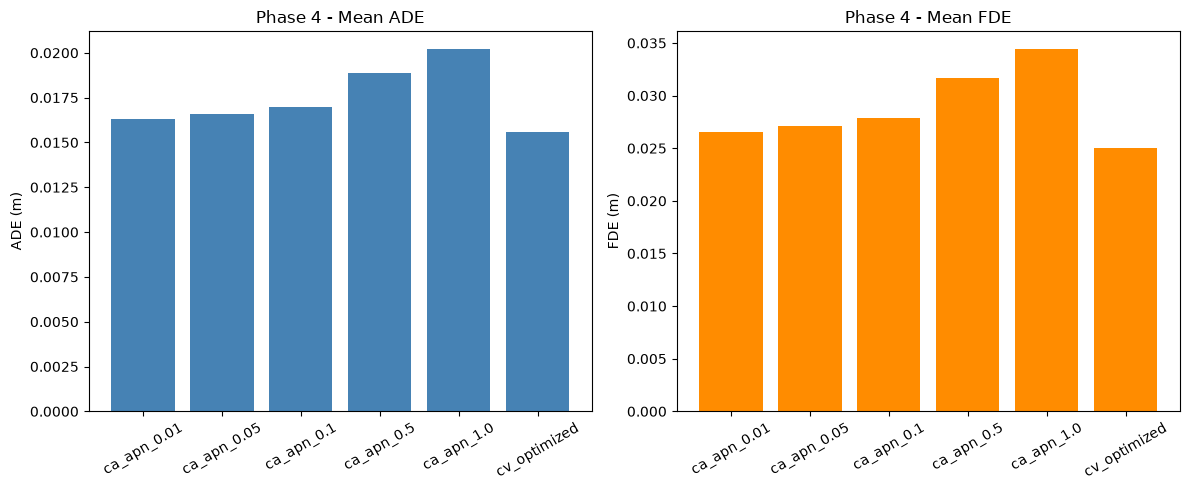

In [106]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.bar(summary["config"], summary["mean_ade"], color="steelblue")
ax1.set_ylabel("ADE (m)")
ax1.set_title(f"Phase {PHASE} - Mean ADE")
ax1.tick_params(axis="x", rotation=30)

ax2.bar(summary["config"], summary["mean_fde"], color="darkorange")
ax2.set_ylabel("FDE (m)")
ax2.set_title(f"Phase {PHASE} - Mean FDE")
ax2.tick_params(axis="x", rotation=30)

fig.tight_layout()
plt.show()

## Per-sequence breakdown

FDE per config, broken out by sequence - helps spot if one trajectory type dominates.

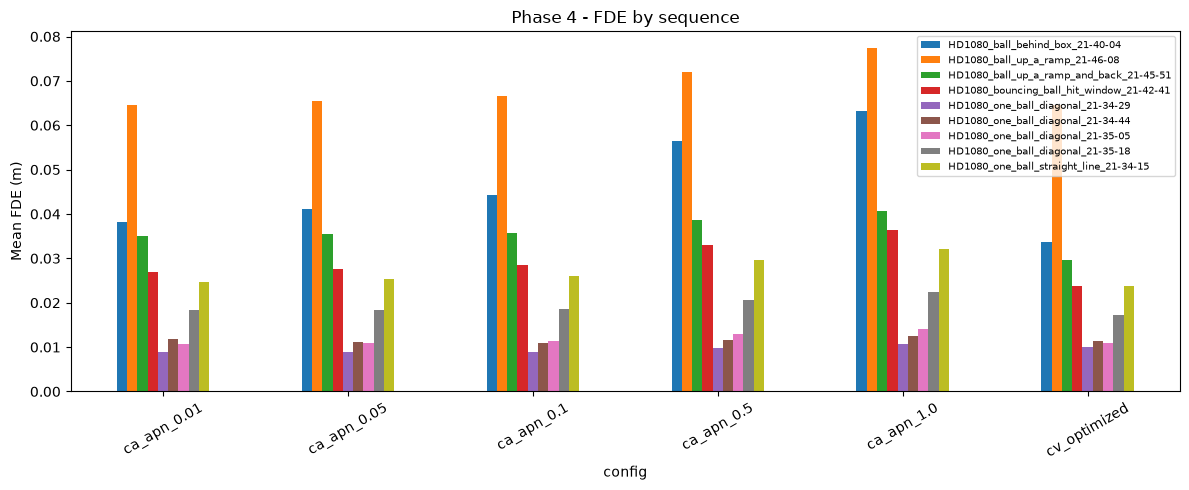

In [107]:
pivot = df.pivot_table(index="config", columns="sequence", values="mean_fde_m")

fig, ax = plt.subplots(figsize=(12, 5))
pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("Mean FDE (m)")
ax.set_title(f"Phase {PHASE} - FDE by sequence")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()

## Cross-phase comparison

Compare the best config from each phase run so far.

In [108]:
phase_bests = []
for p in range(1, PHASE + 1):
    path = OUTPUT_DIR / f"sweep_phase_{p}.csv"
    if not path.exists():
        continue
    phase_df = pd.read_csv(path)
    s = phase_df.groupby("config").agg(
        mean_ade=("mean_ade_m", "mean"),
        mean_fde=("mean_fde_m", "mean"),
    )
    best_row = s.loc[s["mean_fde"].idxmin()]
    phase_bests.append({"phase": p, "config": best_row.name,
                        "mean_ade": best_row["mean_ade"], "mean_fde": best_row["mean_fde"]})

if phase_bests:
    comparison = pd.DataFrame(phase_bests)
    display(comparison)
else:
    print("No phase results found.")

,phase,config,mean_ade,mean_fde
0,1,vpn_0.02,0.00910,0.01466
1,2,ppn_0.0001,0.00910,0.01466
2,3,mnscale_2.0,0.00904,0.01454
3,4,cv_optimized,0.01560,0.02500


## Conclusions

Three parameters of the constant-velocity Kalman filter were swept in isolation across 5 SVO sequences (4 diagonal, 1 straight-line trajectories).

**Phase 1 - velocity process noise** was the most impactful parameter. It controls how quickly the filter adapts to speed changes. A clear U-shaped optimum was found at 0.02: lower values cause the filter to lag behind real velocity changes, higher values amplify measurement noise into the velocity estimate.

**Phase 2 - position process noise** had a moderate effect. The default value (0.0001) was already near-optimal. Increasing it above 0.001 caused the filter to distrust its own physics model and chase raw measurements, degrading prediction accuracy significantly.

**Phase 3 - measurement noise scaling** had negligible impact on mean ADE/FDE (less than 0.4mm variation across a 20x range). The ZED camera noise is small enough that the process noise dominates the Kalman gain regardless of the R scaling.

**Final optimized constant-velocity parameters:**
- `velocity_process_noise`: 0.02
- `position_process_noise`: 0.0001
- measurement noise: ZED-derived (X=6.4e-5, Y=1.21e-4, Z=6.4e-5), no scaling

The remaining prediction error (~0.015m mean FDE at 200ms horizon) is structural - it stems from the constant-velocity assumption, which cannot account for gravity or acceleration. Improving beyond this ceiling requires moving to a constant-acceleration model.